## 原始import

In [1]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pywt
from matplotlib.font_manager import FontProperties
import pickle
import math
import scipy
import scipy.signal
import vector
import json
import zipfile
import os

%matplotlib inline 
#np.set_printoptions(threshold=np.inf)

# pd.set_option('display.max_columns', None) #原来中间会有部分列的显示被省略

## 小仪器数据处理def文件

In [2]:
def filters_main(spec,use_new=2):
    #comprehensive filters that handle the filter process
    #set use_new to 0 if use movemean 20pt, use_new to 1 if fir

    ## baseline 1
    # old mov_mean does not use
    # 输入一个list
    spec=np.array(spec)#转化成numpy形式
    if use_new == 1 or use_new == 2:
        baseline_1 = spec
    else:
        baseline_1 = spec

    ## filter
    if use_new == 2:
        filtered = filter_gaus(baseline_1)
    elif use_new == 0:
        # default 21pt filter
        filtered = filter_mov(baseline_1)

    ## baseline correction2
    if use_new == 1 or use_new == 2:
        out = filtered - matlab_percentile(filtered, 10)
        out[out < 0] = 0
    elif use_new == 0:
        filtered[filtered < 0] = 0
        out = filtered - filtered.min()

    out = out.tolist()
    #print(type(out)) = list
    #print(out) = []
    return(out)

def filter_gaus(input_spec,cycle=1):

    window = 100
    alpha = 6
    std = (window - 1) / (2 * alpha)
    b = scipy.signal.windows.gaussian(window, std, sym=True)
    b = b / sum(b)
    output_spec = np.convolve(input_spec, b,'same')
    for i in range(2, cycle + 1):
        output_spec = np.convolve(input_spec, b,'same')
    return(output_spec)



def filter_mov(input_spec, window=21, cycle=1):
    # input_spec is a 1d array
    # window is the width of the move mean
    # cycle is the repetive number
    use_old = 1
    if use_old != 0:
        MEAN_SIZE = window - 1
        for k in range(1,cycle+1):
            half = MEAN_SIZE/ 2
            npt=MEAN_SIZE+1
            lentmp1=len(input_spec)
            if half < 1:
                tmp =input_spec
            else:
                tmp=[]
                for i in range(0,lentmp1):
                    if i>=0 and i<=half-1 or i>=lentmp1-half-1 and  i<=lentmp1-1:
                        mean_value=math.floor(np.mean(input_spec[0:10]))
                        tmp.append((input_spec[i]-mean_value)/npt+mean_value)
                    else:
                        tmp.append(math.floor(np.mean(input_spec[i-10-1:i+10])))

                tmp = np.array(tmp)
            tmp=np.transpose(tmp)
            output_spec=tmp
    else:

        b = (1 / window) * np.ones(window)
        output_spec=np.convolve(input_spec,b,'same')
        for i in range(2,cycle+1):
            output_spec=np.convolve(input_spec,b,'same')

    return(output_spec)




def matlab_percentile(x, p):
    p = np.asarray(p, dtype=float)
    n = len(x)
    p = (p-50)*n/(n-1) + 50
    p = np.clip(p, 0, 100)
    baseline=np.percentile(x, p)
    return(baseline)

def get_spec_params(data,is_neg=0):
# is_neg=0时：正模式，输入一个参数正模式
    if is_neg: #负模式
        mass_calib_c0 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters_neg']['spec_parameters']['mass_calib_c0']['value']
        mass_calib_c1 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters_neg']['spec_parameters']['mass_calib_c1']['value']
        mass_calib_c2 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters_neg']['spec_parameters']['mass_calib_c2']['value']
        calib_mass_start = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters_neg']['spec_parameters']['calib_mass_start']['value']
    else: #正模式
        mass_calib_c0 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters']['spec_parameters']['mass_calib_c0']['value']
        mass_calib_c1 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters']['spec_parameters']['mass_calib_c1']['value']
        mass_calib_c2 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters']['spec_parameters']['mass_calib_c2']['value']
        calib_mass_start = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters']['spec_parameters']['calib_mass_start']['value']

    return(mass_calib_c0, mass_calib_c1, mass_calib_c2, calib_mass_start)

def Method1_get_filelist(path): #path = 'W:/study/PHD1/检测器tutorial/10.30数据/different_ppm_samePara/20PPM/'  # (一个文件夹)
    file_list = []
    for root, dirs, files in os.walk(path):
        for file in files:
            if 'mrz' in file:
                file_list.append(os.path.join('%s%s' % (root, file)))
  # file_list 是一个list
    return(file_list)
def load_mrz(name):  #filepath = 'W:/study/PHD1/检测器tutorial/10.30数据/different_ppm_samePara/500PPB/1.mrz' , type=mrz
    zfile = zipfile.ZipFile(name)   #zfile.namelist()={'arbitrary_2021_10_30_18_07_11_227.json'}
    if len(zfile.namelist()) ==1:
        for filenames in zfile.namelist():
            zfile.extract(filenames, path=os.getcwd())
            file = os.getcwd() + '/' + filenames
            with open(file, "r", encoding='utf-8') as fp:
                data = json.load(fp)
            if os.path.exists(file):  # 如果文件存在
                os.remove(file)
        return(data)
    
def process_mrz_data(data,use_new_filter=2):
    n=0
    while n<=(len(data['analysis']['scan_list'])-1):
        pt_per_th = data['analysis']['parameters_files']['static_parameters']['static_parameters']['pt_per_th']
        scan_speed = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters']['calib_parameters']['scan_speed']['value']
        if data['analysis']['scan_list'][n]['method_parameters']['polarity'] == "NEG":
            [mass_calib_c0, mass_calib_c1, mass_calib_c2, calib_mass_start] = get_spec_params(data, 1)
        else:
            [mass_calib_c0, mass_calib_c1, mass_calib_c2, calib_mass_start] = get_spec_params(data)

        if type(data['analysis']['scan_list'][n]['raw_data'][0])== "dict":
            print('data是字典结构，请重新调试程序')
            #data['analysis']['scan_list'][n]['filtered']={}
            data['analysis']['scan_list'][n]['mz'] = {}
            for len_data in range(0,len(data['analysis']['scan_list'][n]['data'])):
                if len(data['analysis']['scan_list'][n]['data'][0])==1:
                    if data['analysis']['scan_list'][n].__contains__('raw_counting_data') and data['analysis']['scan_list'][n].__contains__('raw_analog_data'):
                        # filtered the analog data
                        data['analysis']['scan_list'][n]['analog_filtered'] = filters_main(data['analysis']['scan_list'][n]['raw_analog_data'][0],use_new_filter)
                        data['analysis']['scan_list'][n]['analog_filtered'] = [data['analysis']['scan_list'][n]['analog_filtered']]


                if data['analysis']['scan_list'][n]['method_parameters'].__contains__('scan_mass_start') and calib_mass_start != data['analysis']['scan_list'][n]['method_parameters']['scan_mass_start']:
                    x0 = [i+pt_per_th * (data['analysis']['scan_list'][n]['method_parameters']['scan_mass_start']-calib_mass_start) for i in range(0,len_data)]
                    data['analysis']['scan_list'][n]['mz'] = np.polyval([mass_calib_c2, mass_calib_c1, mass_calib_c0], x0).tolist()
                    data['analysis']['scan_list'][n]['mz'] = [data['analysis']['scan_list'][n]['mz']]

                else:
                    x0=[i for i in range(0,len_data)]
                    data['analysis']['scan_list'][n]['mz'] = np.polyval([mass_calib_c2, mass_calib_c1, mass_calib_c0], x0).tolist()
                    data['analysis']['scan_list'][n]['mz'] = [data['analysis']['scan_list'][n]['mz']]


                # prepare the temp
                if data['analysis']['scan_list'][n]['spec_parameters'].__contains__('mass_temp_comp_c0') and data['analysis']['scan_list'][n]['spec_parameters'].__contains__('mass_temp_comp_c1') and data['analysis']['scan_list'][n]['spec_parameters'].__contains__('mass_temp_comp_c2') and data['analysis']['scan_list'][n]['spec_parameters'].__contains__('current_temperature') and data['analysis']['scan_list'][n]['spec_parameters'].__contains__('calib_temperature'):
                    if float(data['analysis']['config']['DataProcessing']['mass_temp_comp_enabled']) == 1:
                        t_c0 = data['analysis']['scan_list'][n]['spec_parameters']['mass_temp_comp_c0']
                        t_c1 = data['analysis']['scan_list'][n]['spec_parameters']['mass_temp_comp_c1']
                        t_c2 = data['analysis']['scan_list'][n]['spec_parameters']['mass_temp_comp_c2']
                        dt = data['analysis']['scan_list'][n]['spec_parameters']['current_temperature'] - data['analysis']['scan_list'][n]['spec_parameters']['calib_temperature']

                        data['analysis']['scan_list'][n]['mz'] = temp_correction(data['analysis']['scan_list'][n]['mz'],t_c0, t_c1, t_c2, dt)
                        data['analysis']['scan_list'][n]['mz'] = [data['analysis']['scan_list'][n]['mz']]

        else:
            data['analysis']['scan_list'][n]['analog_filtered'] = filters_main(data['analysis']['scan_list'][n]['raw_data'], 2)
            data['analysis']['scan_list'][n]['analog_filtered'] = [data['analysis']['scan_list'][n]['analog_filtered']]
            #prepare the mz
            len_data=len(data['analysis']['scan_list'][n]['raw_data'])
            if data['analysis']['scan_list'][n]['method_parameters'].__contains__('scan_mass_start') and calib_mass_start != data['analysis']['scan_list'][n]['method_parameters']['scan_mass_start']:
                x0 = [i+pt_per_th * (data['analysis']['scan_list'][n]['method_parameters']['scan_mass_start']-calib_mass_start) for i in range(0,len_data)]
                data['analysis']['scan_list'][n]['mz'] = np.polyval([mass_calib_c2, mass_calib_c1, mass_calib_c0], x0).tolist()
                data['analysis']['scan_list'][n]['mz'] = [data['analysis']['scan_list'][n]['mz']]
            else:
                x0=[i for i in range(0,len_data)]
                data['analysis']['scan_list'][n]['mz'] = np.polyval([mass_calib_c2, mass_calib_c1, mass_calib_c0], x0).tolist()
                data['analysis']['scan_list'][n]['mz'] = [data['analysis']['scan_list'][n]['mz']]
        n=n+1
    return(data)
                                                        
                                                          
def baseline_delete_method2(raw_data_list):   #所有的数据 按照平均值的正负3倍std,速度很慢
    spec = np.array(raw_data_list)
    baseline = spec
    i = 0
    mean_base=[]
    std_base=[]
    while i < 3 :
        mean_base.append(np.mean(baseline))
        std_base.append(np.std(baseline))
        baseline = spec[np.where(spec<(mean_base[i] + 3*std_base[i]))]
        i = i+1
    if np.size(spec,0)==1:
        filterd_data = spec - np.mean(baseline) # [[class 'numpy.ndarray']]
    else:
        print('请检查raw_data维数')
    return (filterd_data) ## <class 'numpy.ndarray'>

## 获得一个文件夹里所有的文件名称，并生成spectrogram

In [3]:
import os

def Method1_get_filelist(path, file_extension='.mrz',file_start='NMS1-1'):
    file_list = []
    for root, dirs, files in os.walk(path):
        for file in files:
            if file.startswith(file_start) and file.endswith(file_extension):  # 检查文件名前缀和后缀
                file_list.append(os.path.join(root, file))
    return file_list
# Method1_get_filelist('D:/DATA/ZHY/cwt图像处理/2hg/')
# eg: Method1_get_filelist('E:/神经胶质瘤/HS_data_new/1/')


## 获得一组spectrograms，代表一个文件夹里所有spectrogram

In [4]:
import os
import numpy as np
from scipy.linalg import expm, logm
import matplotlib.pyplot as plt

def process_files(folder_path):
    file_list = Method1_get_filelist(folder_path)
    spectrograms = []

# 创建一个用于存放图像的新文件夹
    output_folder = os.path.join(folder_path, 'SpectrogramsPlot')
    if not os.path.exists(output_folder):
        os.makedirs(output_folder)

    for name in file_list:
        data = load_mrz(name)
        data = process_mrz_data(data, use_new_filter=2)

        y_int = data['analysis']['scan_list'][0]['analog_filtered'][0]
        x_mz = data['analysis']['scan_list'][0]['mz'][0]

        plt.plot(x_mz, y_int)
        # 保存图像到新文件夹
        plt.savefig(os.path.join(output_folder, f'{os.path.basename(name)}_plot.svg'), format='svg')
        plt.close()  # 防止显示图像
        spectrogram = np.array([x_mz, y_int])
        spectrograms.append(spectrogram)
        
    return spectrograms


# folder_path = 'D:/DATA/ZHY/cwt图像处理/2hg/'
# spectrograms = process_files(folder_path)

## cwt包装，批量处理数据

In [5]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
def generate_spectrogram(spectrogram):
    """
    根据给定的质谱数据生成时频图。
    """
    # 信号强度
    signal_strength = spectrogram[1]

    # 连续小波变换参数
    wavelet = signal.ricker
    widths = np.arange(1, 100)  # 尺度范围

    # 进行连续小波变换
    cwt_matrix = signal.cwt(signal_strength, wavelet, widths)

    # 获取时间轴和频率轴
    time = spectrogram[0]

    return np.abs(cwt_matrix), time, widths

def plot_spectrogram(cwt_matrix, time, widths):
    """
    绘制时频图
    """
    plt.figure(figsize=(10, 6))
    plt.imshow(cwt_matrix, extent=[time.min(), time.max(), 100, 1], aspect='auto', vmin=cwt_matrix.min(), vmax=cwt_matrix.max())
    plt.colorbar()
    plt.xlabel('Time')
    plt.ylabel('Scale')
    plt.title('Continuous Wavelet Transform Spectrogram')
    plt.show()

#vmin=cwt_matrix.min(), vmax=cwt_matrix.max(): 
#这些参数设置颜色映射的最小值和最大值。
#它们被设置为cwt_matrix的最小值和最大值，颜色将代表矩阵中的最小值和最大值。


## 批量化处理所有质谱图并生成CWT后的时频图

In [6]:
def check_spectrogram_dimensions(spectrograms, expected_shape):
    for spectrogram in spectrograms:
        if spectrogram[0].shape != expected_shape:
            raise ValueError(f"Spectrogram shape mismatch. Expected: {expected_shape}, but got: {spectrogram.shape}")

In [7]:
def integrate_spectrograms(spectrograms):
    # 假设所有时频图都具有相同的维度
    integrated = np.stack([s[0] for s in spectrograms], axis=-1)
    return integrated
    
def batch_process(root_folder):
    '''
    最后生成的type(processed_samples)是list，长度是样本个数，139个
    processed_samples[i]是numpy.ndarray，np.shape是(99, 18229, 1)
    '''
    processed_samples = []
    expected_shape = (99, 18229)
    for folder in os.listdir(root_folder):
        folder_path = os.path.join(root_folder, folder)
        if os.path.isdir(folder_path):
            spectrograms = process_files(folder_path)
            processed_spectrograms = [generate_spectrogram(s) for s in spectrograms]
            #print(folder)
            check_spectrogram_dimensions(processed_spectrograms, expected_shape)
            integrated_spectrograms = integrate_spectrograms(processed_spectrograms)
            if  integrated_spectrograms.shape != (99, 18229, 1):
                print(folder_path)
                raise ValueError("数组形状不符合预期。期望的形状是 (99, 18229, 1)。")
            processed_samples.append(integrated_spectrograms)
    return processed_samples

# 使用批量处理函数
root_folder = 'F:\神经胶质瘤\HS_data_new_CWT' 
processed_samples = batch_process(root_folder)


In [8]:
np.shape(processed_samples[0])


(99, 18229, 1)

### 读取数据和label

In [9]:
import pandas as pd
import re

# Excel文件路径
excel_path = 'F:/神经胶质瘤/HS_data_new/labellist.xlsx'

# 读取Excel文件
df = pd.read_excel(excel_path)

# 筛选第二列值为0或1的行
filtered_df = df[df.iloc[:, 1].isin([0, 1])]

# 将第一列转换为字符串
filtered_df.iloc[:, 0] = filtered_df.iloc[:, 0].astype(str)

# 按第一列字符串排序
sorted_df = filtered_df.sort_values(by=filtered_df.columns[0])

# 查看排序后的DataFrame
print(sorted_df)
labels = sorted_df.iloc[:,1].values

    序号（数据分析用）  IDH_status（0:wt; 1:mt; 2:N; 3:/）
76         10                                 1
56        100                                 0
105       101                                 1
57        102                                 0
106       103                                 1
..        ...                               ...
53         94                                 0
54         95                                 0
103        97                                 1
104        98                                 1
55         99                                 0

[123 rows x 2 columns]


C:\Users\Administrator\AppData\Local\Temp\ipykernel_7832\1698098488.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df.iloc[:, 0] = filtered_df.iloc[:, 0].astype(str)


In [10]:
processed_samples_array=np.array(processed_samples)
np.shape(processed_samples_array)
len(labels)

(123, 99, 18229, 1)

123

# 方法 1：基于区域的裁剪或池化

In [11]:
from skimage.measure import block_reduce
import numpy as np

def pool_spectrogram(spectrogram, pool_size=(2, 2)):
    # 使用平均池化
    return block_reduce(spectrogram, block_size=pool_size, func=np.mean)

# 应用池化
pooled_samples = np.array([pool_spectrogram(sample.squeeze()) for sample in processed_samples_array])

In [12]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

def build_cnn_model(input_shape):
    model = Sequential([
        Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        MaxPooling2D((2, 2)),
        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dense(128, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# 更新输入尺寸
input_shape = (pooled_samples.shape[1], pooled_samples.shape[2], 1)
model = build_cnn_model(input_shape)

In [18]:
from sklearn.model_selection import train_test_split

train_samples, test_samples, train_labels, test_labels = train_test_split(
    pooled_samples, labels, test_size=0.2, random_state=42)

history = model.fit(train_samples, train_labels, epochs=10, batch_size=32, validation_data=(test_samples, test_labels))

Epoch 1/10
4/4 [==============================] - 20s 4s/step - loss: 141791.0000 - accuracy: 0.5714 - val_loss: 3023.5913 - val_accuracy: 0.7200
Epoch 2/10
4/4 [==============================] - 20s 5s/step - loss: 4072.3877 - accuracy: 0.6122 - val_loss: 2124.2134 - val_accuracy: 0.5200
Epoch 3/10
4/4 [==============================] - 21s 5s/step - loss: 1010.3808 - accuracy: 0.5918 - val_loss: 548.1262 - val_accuracy: 0.5200
Epoch 4/10
4/4 [==============================] - 21s 5s/step - loss: 427.9137 - accuracy: 0.6633 - val_loss: 412.7020 - val_accuracy: 0.5200
Epoch 5/10
4/4 [==============================] - 20s 5s/step - loss: 273.5043 - accuracy: 0.6735 - val_loss: 85.3882 - val_accuracy: 0.6400
Epoch 6/10
4/4 [==============================] - 20s 5s/step - loss: 46.7955 - accuracy: 0.6633 - val_loss: 15.3059 - val_accuracy: 0.5200
Epoch 7/10
4/4 [==============================] - 21s 5s/step - loss: 7.9418 - accuracy: 0.6939 - val_loss: 18.4163 - val_accuracy: 0.5600
Epoch

D:\Software\Anaconda3\lib\site-packages\keras\src\engine\training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


Text(0.5, 0, 'Epochs')

Text(0, 0.5, 'Accuracy')

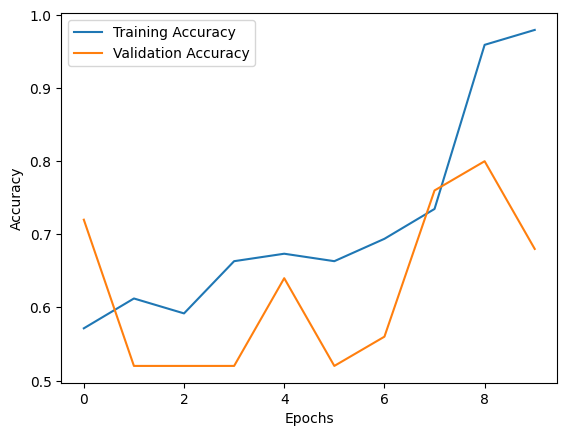

In [19]:
import matplotlib.pyplot as plt

model.save('cnn_model.h5')

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# 方法 2：特征提取和降维

In [20]:
from sklearn.decomposition import PCA

# 假设降维到100个特征
pca = PCA(n_components=100)
flat_samples = processed_samples_array.reshape(123, -1)
reduced_samples = pca.fit_transform(flat_samples)

In [21]:
def build_fc_model(input_dim):
    model = Sequential([
        Dense(128, activation='relu', input_dim=input_dim),
        Dense(64, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

model_fc = build_fc_model(100)

In [22]:
train_samples, test_samples, train_labels, test_labels = train_test_split(
    reduced_samples, labels, test_size=0.2, random_state=42)

history_fc = model_fc.fit(train_samples, train_labels, epochs=10, batch_size=32, validation_data=(test_samples, test_labels))

Epoch 1/10
4/4 [==============================] - 1s 58ms/step - loss: 97880.9375 - accuracy: 0.4796 - val_loss: 22443.1934 - val_accuracy: 0.6000
Epoch 2/10
4/4 [==============================] - 0s 18ms/step - loss: 40494.0000 - accuracy: 0.7143 - val_loss: 19795.1758 - val_accuracy: 0.6000
Epoch 3/10
4/4 [==============================] - 0s 17ms/step - loss: 19118.0703 - accuracy: 0.8776 - val_loss: 17495.2832 - val_accuracy: 0.6000
Epoch 4/10
4/4 [==============================] - 0s 18ms/step - loss: 8046.2231 - accuracy: 0.8980 - val_loss: 21237.3867 - val_accuracy: 0.6800
Epoch 5/10
4/4 [==============================] - 0s 18ms/step - loss: 2560.4121 - accuracy: 0.9388 - val_loss: 23932.2168 - val_accuracy: 0.7200
Epoch 6/10
4/4 [==============================] - 0s 16ms/step - loss: 2983.7168 - accuracy: 0.9082 - val_loss: 25247.5684 - val_accuracy: 0.6800
Epoch 7/10
4/4 [==============================] - 0s 18ms/step - loss: 1016.0323 - accuracy: 0.9796 - val_loss: 35096.621

D:\Software\Anaconda3\lib\site-packages\keras\src\engine\training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


Text(0.5, 0, 'Epochs')

Text(0, 0.5, 'Accuracy')

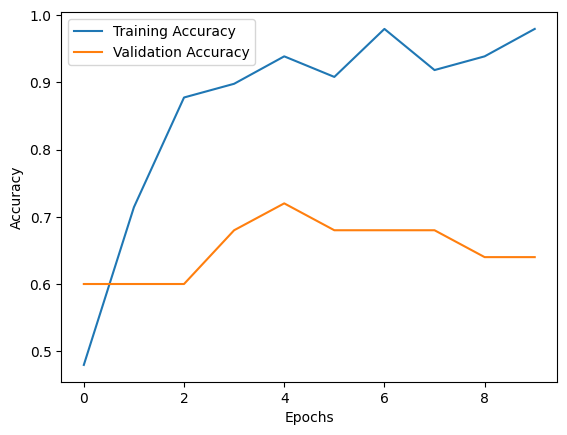

In [23]:
model_fc.save('fc_model.h5')

plt.plot(history_fc.history['accuracy'], label='Training Accuracy')
plt.plot(history_fc.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# 方法 3：数据分块处理

In [26]:
def split_spectrogram(spectrogram, num_splits):
    split_size = spectrogram.shape[1] // num_splits
    return [spectrogram[:, i*split_size:(i+1)*split_size, :] for i in range(num_splits)]

num_splits = 10  # 示例，将18229分为10块
split_samples = [split_spectrogram(sample, num_splits) for sample in processed_samples_array]
split_samples = np.array(split_samples).reshape(-1, 99, 18229//num_splits, 1)  # 调整形状以适应模型

In [27]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

def build_cnn_model(input_shape):
    model = Sequential([
        Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        MaxPooling2D((2, 2)),
        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dense(128, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

model = build_cnn_model(split_samples[0].shape)

In [28]:
from sklearn.model_selection import train_test_split

# 由于分块，需要扩展标签数组
extended_labels = np.repeat(labels, num_splits)

train_samples, test_samples, train_labels, test_labels = train_test_split(
    split_samples, extended_labels, test_size=0.2, random_state=42)

history = model.fit(train_samples, train_labels, epochs=10, batch_size=32, validation_data=(test_samples, test_labels))

Epoch 1/10
31/31 [==============================] - 73s 2s/step - loss: 17489.6973 - accuracy: 0.4756 - val_loss: 0.6940 - val_accuracy: 0.3333
Epoch 2/10
31/31 [==============================] - 75s 2s/step - loss: 0.6932 - accuracy: 0.5000 - val_loss: 0.6923 - val_accuracy: 0.6667
Epoch 3/10
31/31 [==============================] - 76s 2s/step - loss: 0.6922 - accuracy: 0.5854 - val_loss: 0.6900 - val_accuracy: 0.6667
Epoch 4/10
31/31 [==============================] - 77s 2s/step - loss: 0.6910 - accuracy: 0.5854 - val_loss: 0.6878 - val_accuracy: 0.6667
Epoch 5/10
31/31 [==============================] - 77s 2s/step - loss: 0.6899 - accuracy: 0.5854 - val_loss: 0.6855 - val_accuracy: 0.6667
Epoch 6/10
31/31 [==============================] - 77s 2s/step - loss: 0.6888 - accuracy: 0.5854 - val_loss: 0.6831 - val_accuracy: 0.6667
Epoch 7/10
31/31 [==============================] - 77s 2s/step - loss: 0.6878 - accuracy: 0.5854 - val_loss: 0.6808 - val_accuracy: 0.6667
Epoch 8/10
31/31

D:\Software\Anaconda3\lib\site-packages\keras\src\engine\training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


Text(0.5, 1.0, 'Model Accuracy')

Text(0, 0.5, 'Accuracy')

Text(0.5, 0, 'Epoch')

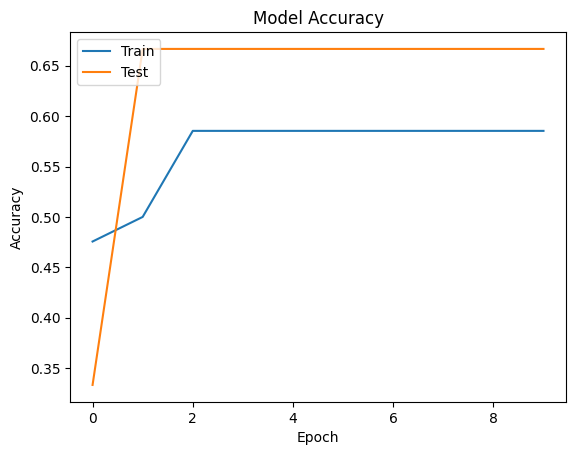

Text(0.5, 1.0, 'Model Loss')

Text(0, 0.5, 'Loss')

Text(0.5, 0, 'Epoch')

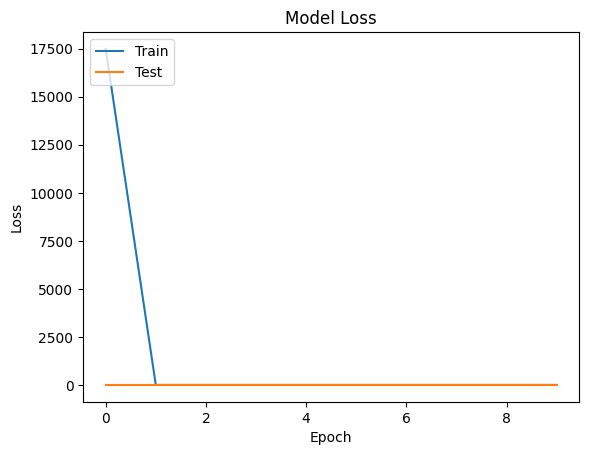

In [29]:
model.save('my_cnn_model.h5')
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

In [30]:
from tensorflow.keras.models import Model

def display_activation(activations, num_col, num_row, layer_index):
    activation = activations[layer_index]
    fig, axes = plt.subplots(num_row, num_col, figsize=(num_row*2.5, num_col*1.5))
    for i in range(num_row*num_col):
        if i < activation.shape[-1]:
            ax = axes[i // num_col, i % num_col]
            ax.imshow(activation[0, :, :, i], cmap='viridis')
            ax.set_xticks([])
            ax.set_yticks([])
        else:
            axes[i // num_col, i % num_col].axis('off')
    plt.tight_layout()
    plt.show()

# 选择一个样本
sample = split_samples[0:1]

# 创建一个模型，给出输入图片并输出卷积层的激活值
layer_outputs = [layer.output for layer in model.layers if 'conv' in layer.name]
activation_model = Model(inputs=model.input, outputs=layer_outputs)
activations = activation_model.predict(sample)

# 可视化第一个卷积层的激活
display_activation

1/1 [==============================] - 0s 251ms/step


<function __main__.display_activation(activations, num_col, num_row, layer_index)>

In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense

def build_1d_cnn_model(input_shape):
    model = Sequential([
        Conv2D(32, kernel_size=(5, 5), activation='relu', input_shape=input_shape),
        MaxPooling2D(pool_size=(2, 2)),
        Conv2D(64, kernel_size=(5, 5), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.25),
        Conv2D(128, kernel_size=(3, 3), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),
        Flatten(),
        Dense(256, activation='relu'),
        Dropout(0.5),
        Dense(1, activation='sigmoid')  # 假设是二分类问题
    ])
    
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# 调整数据维度以适应1D CNN
processed_samples_1d = processed_samples_array.reshape(123, 18229, 99)

# 构建模型
model_1d_cnn = build_1d_cnn_model((18229, 99))

from scipy.signal import stft

def apply_stft(spectrogram, fs=1.0, nperseg=99):
    _, _, Zxx = stft(spectrogram[:, :, 0], fs=fs, nperseg=nperseg)
    return np.abs(Zxx)

# 示例：对每个样本应用STFT
stft_spectrograms = [apply_stft(sample) for sample in processed_samples_array]

from sklearn.model_selection import train_test_split

# 假设labels是标签数据
# 选择处理后的数据进行训练，例如：stft_spectrograms, cropped_spectrograms 或 processed_samples_1d
train_samples, test_samples, train_labels, test_labels = train_test_split(
    processed_samples_1d, labels, test_size=0.2, random_state=42)

history = model_1d_cnn.fit(
    np.array(train_samples), train_labels, 
    epochs=10, 
    batch_size=32, 
    validation_data=(np.array(test_samples), test_labels)
)

Epoch 1/10
4/4 [==============================] - 4s 711ms/step - loss: 209625.7500 - accuracy: 0.4898 - val_loss: 67880.7031 - val_accuracy: 0.6000
Epoch 2/10
4/4 [==============================] - 2s 576ms/step - loss: 30276.1836 - accuracy: 0.6939 - val_loss: 67655.1172 - val_accuracy: 0.5600
Epoch 3/10
4/4 [==============================] - 2s 560ms/step - loss: 44801.4141 - accuracy: 0.6429 - val_loss: 62860.8555 - val_accuracy: 0.5600
Epoch 4/10
4/4 [==============================] - 3s 611ms/step - loss: 43053.9336 - accuracy: 0.7041 - val_loss: 19578.5449 - val_accuracy: 0.7200
Epoch 5/10
4/4 [==============================] - 2s 599ms/step - loss: 4611.1875 - accuracy: 0.8061 - val_loss: 19162.5117 - val_accuracy: 0.6400
Epoch 6/10
4/4 [==============================] - 3s 612ms/step - loss: 4560.0991 - accuracy: 0.8367 - val_loss: 15590.8350 - val_accuracy: 0.7600
Epoch 7/10
4/4 [==============================] - 3s 628ms/step - loss: 4775.8599 - accuracy: 0.8163 - val_loss: 

## CNN模型构建

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization

def build_complex_cnn_model():
    model = Sequential([
        Conv2D(64, (3, 3), activation='relu', input_shape=(99, 18229, 1), padding='same'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Conv2D(128, (3, 3), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Conv2D(256, (3, 3), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dense(256, activation='relu'),
        Dropout(0.5),
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(1, activation='sigmoid')
    ])

    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# 创建模型
complex_cnn_model = build_complex_cnn_model()

In [ ]:
np.shape(labels)
np.shape(processed_samples[0])

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense
def build_1d_cnn_model(input_shape):
    model = Sequential([
        Conv1D(32, 3, activation='relu', input_shape=input_shape),
        MaxPooling1D(2),
        Conv1D(64, 3, activation='relu'),
        MaxPooling1D(2),
        Flatten(),
        Dense(128, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model
    
model = build_1d_cnn_model((18229, 99))

In [ ]:
from sklearn.model_selection import train_test_split
# 将这些样本堆叠成一个大的数组
processed_samples_array = np.array(processed_samples)
# 假设processed_samples和labels已定义
train_samples, test_samples, train_labels, test_labels = train_test_split(
    processed_samples_1d, labels, test_size=0.2, random_state=42)
model.fit(train_samples, train_labels, epochs=10, batch_size=8, validation_data=(test_samples, test_labels))

In [ ]:
for i, sample in enumerate(processed_samples):
    if sample.shape != (99, 18229, 1):
        print(f"Sample {i} has inconsistent shape: {sample.shape}")

## 结果可视化

### 特征可视化

In [ ]:
import matplotlib.pyplot as plt

def visualize_conv_weights(model, layer_name):
    layer = model.get_layer(name=layer_name)
    weights = layer.get_weights()[0]
    filter_count = weights.shape[-1]

    plt.figure(figsize=(10, 10))
    for i in range(filter_count):
        plt.subplot(8, 8, i+1)  # 假设您想在8x8网格上可视化滤波器
        plt.imshow(weights[:, :, :, i], cmap='gray')
        plt.axis('off')
    plt.show()

# 使用此函数来可视化第一个卷积层的权重
visualize_conv_weights(complex_cnn_model, 'conv2d')

### 绘制训练和验证准确率曲线

In [ ]:
def plot_training_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(len(acc))

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'b', label='Training accuracy')
    plt.plot(epochs, val_acc, 'r', label='Validation accuracy')
    plt.title('Training and validation accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'b', label='Training loss')
    plt.plot(epochs, val_loss, 'r', label='Validation loss')
    plt.title('Training and validation loss')
    plt.legend()

    plt.show()

# 使用此函数来绘制训练和验证准确率曲线
history = complex_cnn_model.fit(...)
plot_training_history(history)

# 数据增强

Epoch 1/20
4/4 [==============================] - 5s 943ms/step - loss: 14749.8613 - accuracy: 0.6735 - val_loss: 2203.9558 - val_accuracy: 0.5200
Epoch 2/20
4/4 [==============================] - 3s 779ms/step - loss: 927.3527 - accuracy: 0.7245 - val_loss: 484.0564 - val_accuracy: 0.5600
Epoch 3/20
4/4 [==============================] - 3s 777ms/step - loss: 226.4522 - accuracy: 0.6429 - val_loss: 245.3079 - val_accuracy: 0.4800
Epoch 4/20
4/4 [==============================] - 3s 770ms/step - loss: 143.3918 - accuracy: 0.6633 - val_loss: 37.6637 - val_accuracy: 0.5600
Epoch 5/20
4/4 [==============================] - 3s 773ms/step - loss: 11.6841 - accuracy: 0.6735 - val_loss: 15.1303 - val_accuracy: 0.8000
Epoch 6/20
4/4 [==============================] - 3s 773ms/step - loss: 6.8923 - accuracy: 0.7857 - val_loss: 11.0944 - val_accuracy: 0.7600
Epoch 7/20
4/4 [==============================] - 3s 782ms/step - loss: 6.1554 - accuracy: 0.7857 - val_loss: 8.4308 - val_accuracy: 0.6400

<Figure size 1200x500 with 0 Axes>

<Axes: >

Text(0.5, 1.0, 'Model Accuracy')

Text(0.5, 0, 'Epoch')

Text(0, 0.5, 'Accuracy')

<Axes: >

Text(0.5, 1.0, 'Model Loss')

Text(0.5, 0, 'Epoch')

Text(0, 0.5, 'Loss')

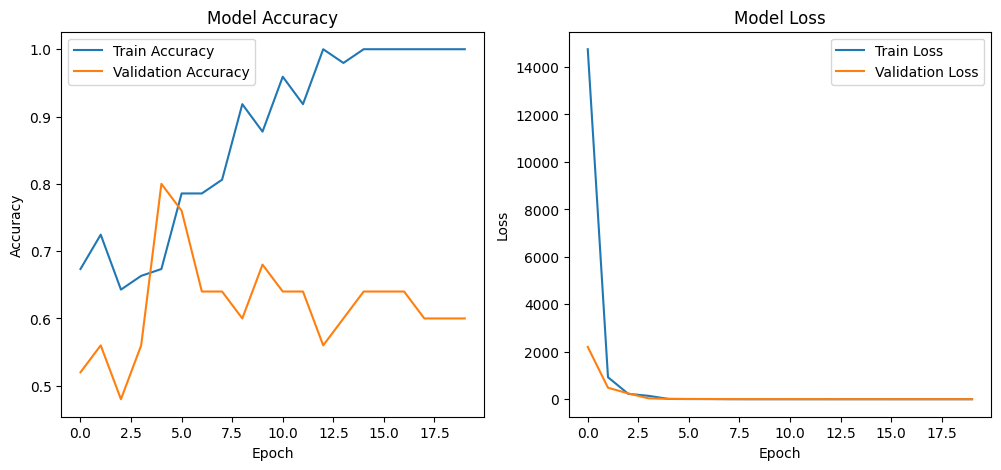

In [71]:
from skimage.measure import block_reduce
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split

# 数据维度减少
def reduce_dimensions(sample, pool_size=(2, 20)):
    """
    使用池化减少样本维度。
    """
    return block_reduce(sample, block_size=pool_size, func=np.mean)

# 应用池化降低维度
pooled_samples = np.array([reduce_dimensions(sample.squeeze()) for sample in processed_samples])

# 数据增强配置
def augment_data(samples):
    """
    使用随机噪声增强数据。
    """
    noise_factor = 0.01
    augmented_samples = samples + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=samples.shape)
    return augmented_samples

# 增强数据
augmented_samples = augment_data(pooled_samples)

# 划分数据集
train_samples, test_samples, train_labels, test_labels = train_test_split(
    augmented_samples, labels, test_size=0.2, random_state=42)

# 构建CNN模型
def build_cnn_model(input_shape):
    model = Sequential([
        Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        MaxPooling2D((2, 2)),
        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dense(128, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# 获取样本的维度
input_shape = (train_samples.shape[1], train_samples.shape[2], 1)

# 初始化并训练模型
model = build_cnn_model(input_shape)
history = model.fit(train_samples, train_labels, epochs=20, batch_size=32, validation_data=(test_samples, test_labels))

# 可视化训练过程
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


<Figure size 1200x500 with 0 Axes>

<Axes: >

Text(0.5, 1.0, 'Model Accuracy')

Text(0.5, 0, 'Epoch')

Text(0, 0.5, 'Accuracy')

<Axes: >

Text(0.5, 1.0, 'Model Loss')

Text(0.5, 0, 'Epoch')

Text(0, 0.5, 'Loss')

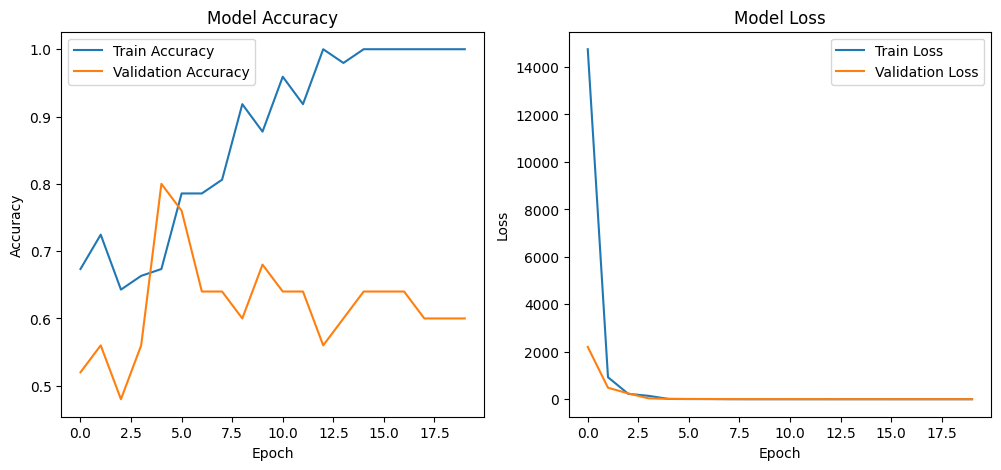

In [73]:
# 可视化训练过程
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.savefig('training_resultsloss.svg', format='svg')
plt.show()


Epoch 1/20
19/19 [==============================] - 163s 8s/step - loss: 22.8496 - accuracy: 0.5085 - val_loss: 0.8055 - val_accuracy: 0.4459
Epoch 2/20
19/19 [==============================] - 108s 6s/step - loss: 0.7108 - accuracy: 0.5695 - val_loss: 0.7127 - val_accuracy: 0.7027
Epoch 3/20
19/19 [==============================] - 110s 6s/step - loss: 0.6941 - accuracy: 0.5763 - val_loss: 0.6436 - val_accuracy: 0.7027
Epoch 4/20
19/19 [==============================] - 109s 6s/step - loss: 0.6750 - accuracy: 0.5627 - val_loss: 0.6697 - val_accuracy: 0.6959
Epoch 5/20
19/19 [==============================] - 109s 6s/step - loss: 0.6971 - accuracy: 0.5864 - val_loss: 0.6579 - val_accuracy: 0.7027
Epoch 6/20
19/19 [==============================] - 108s 6s/step - loss: 0.6628 - accuracy: 0.5983 - val_loss: 0.6640 - val_accuracy: 0.6892
Epoch 7/20
19/19 [==============================] - 108s 6s/step - loss: 0.6590 - accuracy: 0.6034 - val_loss: 0.6759 - val_accuracy: 0.6216
Epoch 8/20
1

<Figure size 1200x500 with 0 Axes>

<Axes: >

Text(0.5, 1.0, 'Model Accuracy')

Text(0.5, 0, 'Epoch')

Text(0, 0.5, 'Accuracy')

<Axes: >

Text(0.5, 1.0, 'Model Loss')

Text(0.5, 0, 'Epoch')

Text(0, 0.5, 'Loss')

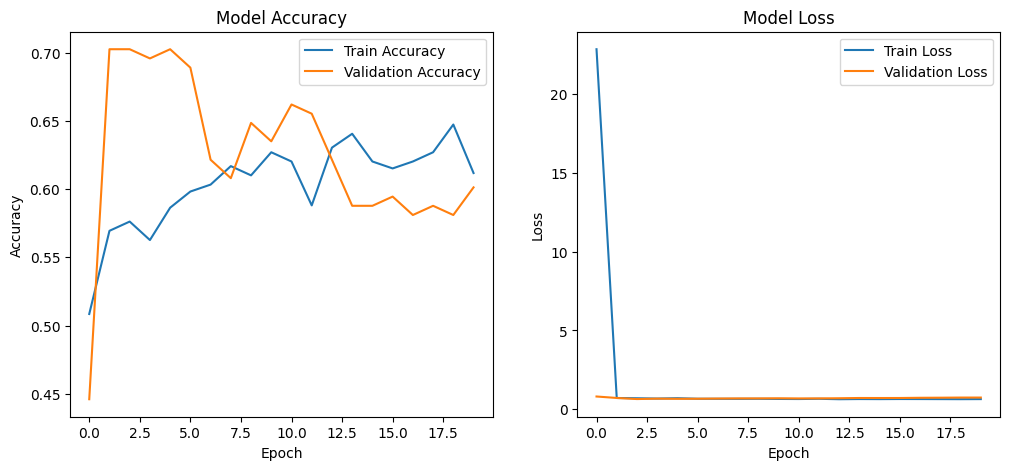

In [65]:
import numpy as np
from skimage.measure import block_reduce
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# 函数：使用池化减少样本维度
def reduce_dimensions(sample, pool_size=(2, 20)):
    return block_reduce(sample, block_size=pool_size, func=np.mean)

# 函数：数据增强
def augment_data(samples, num_augments_per_sample=5):
    noise_factor = 0.0
    augmented_samples = []
    for sample in samples:
        for _ in range(num_augments_per_sample):
            noisy_sample = sample + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=sample.shape)
            augmented_samples.append(noisy_sample)
    return np.array(augmented_samples)

# 假设 processed_samples_array 是原始的时频图数据
pooled_samples = np.array([reduce_dimensions(sample.squeeze()) for sample in processed_samples_array])
augmented_samples = augment_data(pooled_samples)

# 合并原始和增强的样本及其标签
total_samples = np.concatenate([pooled_samples, augmented_samples], axis=0)
total_labels = np.concatenate([labels, np.tile(labels, len(augmented_samples) // len(labels))], axis=0)

# 划分数据集
train_samples, test_samples, train_labels, test_labels = train_test_split(
    total_samples, total_labels, test_size=0.2, random_state=42)

#### 2. 构建更复杂的CNN模型
def build_cnn_model(input_shape):
    model = Sequential([
        Conv2D(64, (3, 3), padding='same', activation='relu', input_shape=input_shape),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Conv2D(128, (3, 3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Conv2D(256, (3, 3), padding='same', activation='relu'),
        Dropout(0.5),
        Flatten(),
        Dense(256, activation='relu'),
        Dropout(0.5),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# 获取样本的维度并初始化模型
input_shape = (train_samples.shape[1], train_samples.shape[2], 1)
model = build_cnn_model(input_shape)

# 模型训练
history = model.fit(train_samples, train_labels, epochs=20, batch_size=32, validation_data=(test_samples, test_labels))

#### 3. 可视化模型的训练结果
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

<Figure size 1200x500 with 0 Axes>

<Axes: >

Text(0.5, 1.0, 'Model Accuracy')

Text(0.5, 0, 'Epoch')

Text(0, 0.5, 'Accuracy')

<Axes: >

Text(0.5, 1.0, 'Model Loss')

Text(0.5, 0, 'Epoch')

Text(0, 0.5, 'Loss')

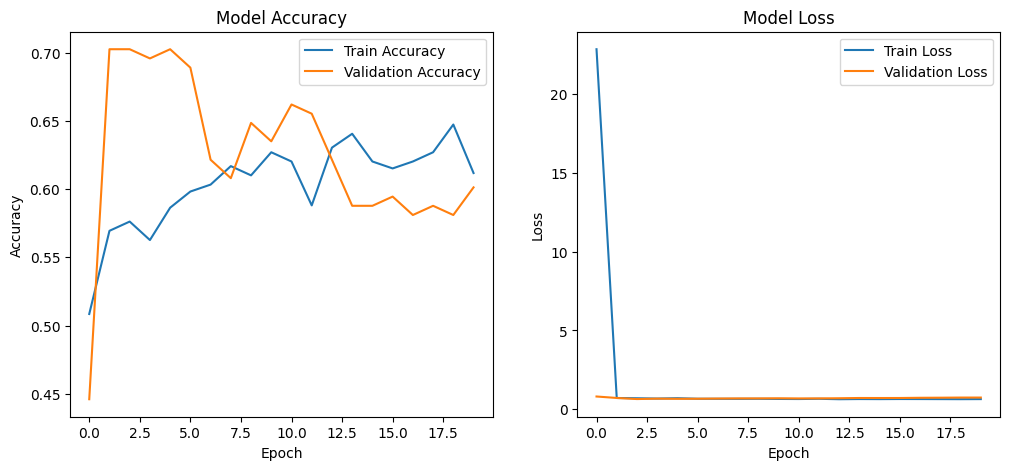

In [70]:
#### 3. 可视化模型的训练结果
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
# 保存图像为SVG格式
plt.savefig('training_results.svg', format='svg')
plt.show()

In [ ]:
a

<Figure size 1200x600 with 0 Axes>

<Axes: >

Text(0.5, 1.0, 'Original Sample')

<Axes: >

Text(0.5, 1.0, 'Pooled Sample')

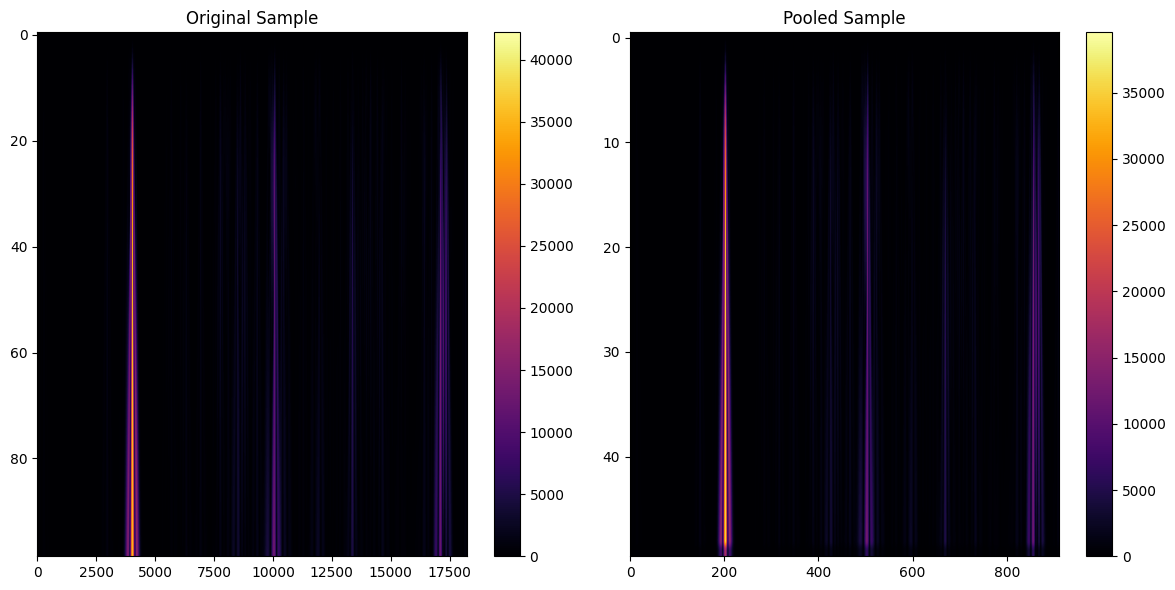

In [40]:
import matplotlib.pyplot as plt

# 假设你有一个原始样本和它对应的池化样本
original_sample = processed_samples[0].squeeze()  # 假设 processed_samples 是未压缩的
pooled_sample = pooled_samples[0]  # 从上述池化后的结果中获取

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(original_sample, aspect='auto', cmap='inferno')
plt.title('Original Sample')
plt.colorbar()

plt.subplot(1, 2, 2)
plt.imshow(pooled_sample, aspect='auto', cmap='inferno')
plt.title('Pooled Sample')
plt.colorbar()

plt.tight_layout()
plt.show()

In [37]:
np.shape(pooled_sample)

(50, 912)

<Figure size 1200x600 with 0 Axes>

<Axes: >

Text(0.5, 1.0, 'Original Sample')

<Axes: >

Text(0.5, 1.0, 'Augmented Sample with Noise')

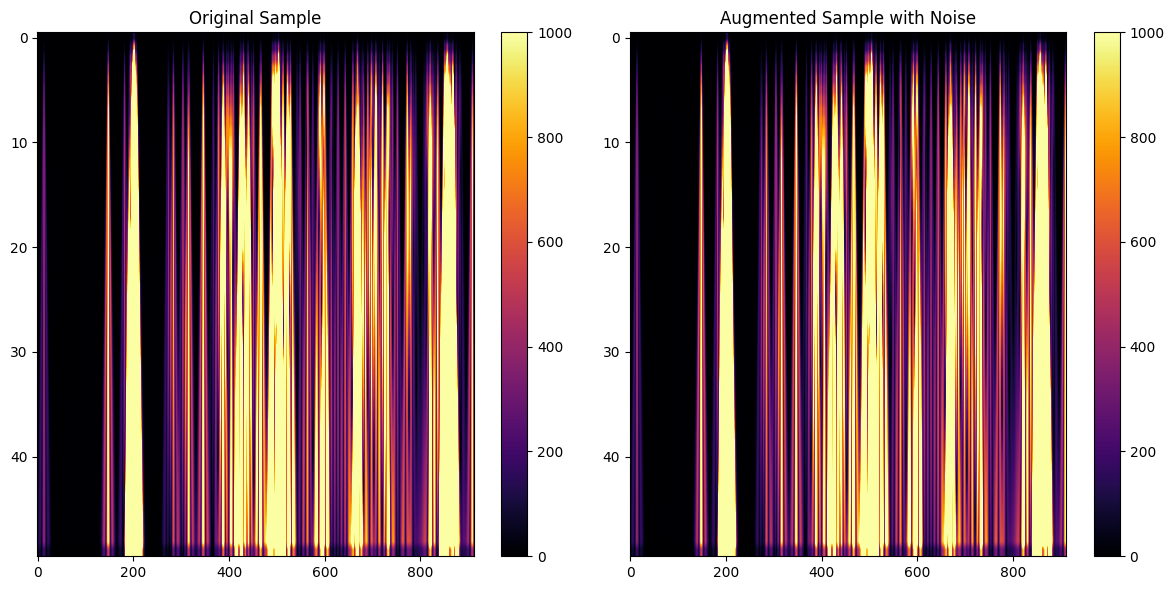

In [33]:
import matplotlib.pyplot as plt
import numpy as np
# 函数：数据增强
def augment_data(samples, num_augments_per_sample=5):
    noise_factor = 0.1
    augmented_samples = []
    for sample in samples:
        for _ in range(num_augments_per_sample):
            noisy_sample = sample + noise_factor * np.random.normal(loc=-1.0, scale=1.0, size=sample.shape)
            augmented_samples.append(noisy_sample)
    return np.array(augmented_samples)
# 假设 pooled_samples 是池化后但未增强的样本
# augmented_samples 是通过 augment_data 函数增强后的样本
original_sample = pooled_samples[0]  # 取一个原始样本
augmented_sample = augmented_samples[0]  # 假设这是相对应的增强样本

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(original_sample, aspect='auto', cmap='inferno', vmin=0, vmax=1000)
plt.title('Original Sample')
plt.colorbar()

plt.subplot(1, 2, 2)
plt.imshow(augmented_sample, aspect='auto', cmap='inferno', vmin=0, vmax=1000)
plt.title('Augmented Sample with Noise')
plt.colorbar()

plt.tight_layout()
plt.show()

In [36]:
from skimage.metrics import mean_squared_error, structural_similarity

mse = mean_squared_error(original_sample, augmented_sample)
ssim = structural_similarity(original_sample, augmented_sample)

print("Mean Squared Error:", mse)
print("Structural Similarity Index:", ssim)

ValueError: Since image dtype is floating point, you must specify the data_range parameter. Please read the documentation carefully (including the note). It is recommended that you always specify the data_range anyway.

# 模型可视化

Model: "sequential_12"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_32 (Conv2D)          (None, 36, 908, 32)       832       
                                                                 
 max_pooling2d_27 (MaxPooli  (None, 18, 454, 32)       0         
 ng2D)                                                           
                                                                 
 conv2d_33 (Conv2D)          (None, 14, 450, 64)       51264     
                                                                 
 max_pooling2d_28 (MaxPooli  (None, 7, 225, 64)        0         
 ng2D)                                                           
                                                                 
 dropout_16 (Dropout)        (None, 7, 225, 64)        0         
                                                                 
 conv2d_34 (Conv2D)          (None, 5, 223, 128)     

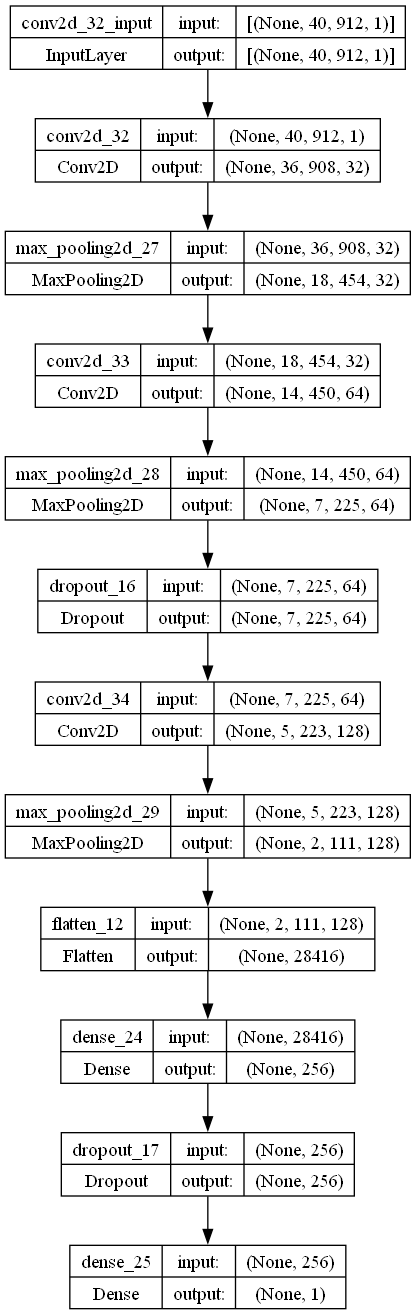

In [66]:
from tensorflow.keras.utils import plot_model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

def build_large_input_cnn(input_shape):
    model = Sequential([
        Conv2D(32, kernel_size=(5, 5), activation='relu', input_shape=input_shape),
        MaxPooling2D(pool_size=(2, 2)),
        Conv2D(64, kernel_size=(5, 5), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.25),
        Conv2D(128, kernel_size=(3, 3), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),
        Flatten(),
        Dense(256, activation='relu'),
        Dropout(0.5),
        Dense(1, activation='sigmoid')  # 假设是二分类问题
    ])
    
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# 假设你的输入尺寸是 (50, 912, 1)
model = build_large_input_cnn((40, 912, 1))
model.summary()
# 假设你的模型已经通过build_cnn_model函数构建并赋值给了model变量
plot_model(model, to_file='model.png', show_shapes=True, show_layer_names=True)

In [43]:
def time_shift(sample, shift_max=50):
    shift = np.random.randint(-shift_max, shift_max)
    return np.roll(sample, shift, axis=1)

def frequency_mask(sample, mask_percentage=0.1):
    num_frequency = sample.shape[0]
    f = np.random.randint(0, num_frequency * (1 - mask_percentage))
    mask_end = int(f + num_frequency * mask_percentage)
    sample[f:mask_end, :] = 0
    return sample

def time_scale(sample, scale=1.2):
    from scipy.ndimage import zoom
    scaled = zoom(sample, (1, scale), order=1)
    if scale > 1:
        return scaled[:, :sample.shape[1]]
    else:
        pad_width = sample.shape[1] - scaled.shape[1]
        return np.pad(scaled, ((0, 0), (0, pad_width)), mode='constant', constant_values=0)

def augment_data(samples, num_augments_per_sample=5):
    augmented_samples = []
    for sample in samples:
        for _ in range(num_augments_per_sample):
            sample_aug = sample.copy()
            if np.random.rand() < 0.5:
                sample_aug = time_shift(sample_aug)
            if np.random.rand() < 0.5:
                sample_aug = frequency_mask(sample_aug)
            if np.random.rand() < 0.5:
                sample_aug = time_scale(sample_aug)
            noisy_sample = add_noise(sample_aug)
            augmented_samples.append(noisy_sample)
    return np.array(augmented_samples)
# 原始数据训练模型
model_original = build_cnn_model(input_shape)
history_original = model_original.fit(train_samples, train_labels, epochs=10, batch_size=32, validation_data=(test_samples, test_labels))

# 增强数据训练模型
augmented_samples = augment_data(pooled_samples)
total_augmented_samples = np.concatenate([pooled_samples, augmented_samples], axis=0)
total_augmented_labels = np.concatenate([labels, np.tile(labels, len(augmented_samples) // len(labels) + 1)], axis=0)

train_aug_samples, test_aug_samples, train_aug_labels, test_aug_labels = train_test_split(
    total_augmented_samples, total_augmented_labels, test_size=0.2, random_state=42)

model_augmented = build_cnn_model(input_shape)
history_augmented = model_augmented.fit(train_aug_samples, train_aug_labels, epochs=10, batch_size=32, validation_data=(test_aug_samples, test_aug_labels))

# 可视化对比结果
plt.figure(figsize=(12, 10))
plt.subplot(2, 2, 1)
plt.plot(history_original.history['accuracy'], label='Train Accuracy (Original)')
plt.plot(history_original.history['val_accuracy'], label='Validation Accuracy (Original)')
plt.title('Model Accuracy (Original)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(2, 2, 2)
plt.plot(history_original.history['loss'], label='Train Loss (Original)')
plt.plot(history_original.history['val_loss'], label='Validation Loss (Original)')
plt.title('Model Loss (Original)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(2, 2, 3)
plt.plot(history_augmented.history['accuracy'], label='Train Accuracy (Augmented)')
plt.plot(history_augmented.history['val_accuracy'], label='Validation Accuracy (Augmented)')
plt.title('Model Accuracy (Augmented)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(2, 2, 4)
plt.plot(history_augmented.history['loss'], label='Train Loss (Augmented)')
plt.plot(history_augmented.history['val_loss'], label='Validation Loss (Augmented)')
plt.title('Model Loss (Augmented)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


Epoch 1/10
19/19 [==============================] - 56s 3s/step - loss: 13.2437 - accuracy: 0.5136 - val_loss: 3.3090 - val_accuracy: 0.6959
Epoch 2/10
19/19 [==============================] - 59s 3s/step - loss: 0.9299 - accuracy: 0.5339 - val_loss: 0.6736 - val_accuracy: 0.6757
Epoch 3/10
19/19 [==============================] - 59s 3s/step - loss: 0.6733 - accuracy: 0.5966 - val_loss: 0.6716 - val_accuracy: 0.6959
Epoch 4/10
19/19 [==============================] - 60s 3s/step - loss: 0.6673 - accuracy: 0.5949 - val_loss: 0.6706 - val_accuracy: 0.6622
Epoch 5/10
19/19 [==============================] - 59s 3s/step - loss: 0.6553 - accuracy: 0.6339 - val_loss: 0.6848 - val_accuracy: 0.6149
Epoch 6/10
19/19 [==============================] - 60s 3s/step - loss: 0.6536 - accuracy: 0.6339 - val_loss: 0.6893 - val_accuracy: 0.5878
Epoch 7/10
19/19 [==============================] - 60s 3s/step - loss: 0.6462 - accuracy: 0.6475 - val_loss: 0.7038 - val_accuracy: 0.5000
Epoch 8/10
19/19 [=

ValueError: Found input variables with inconsistent numbers of samples: [738, 861]

In [47]:
np.shape(total_augmented_samples)

(738, 50, 912)

<Figure size 1200x600 with 0 Axes>

<Axes: >

Text(0.5, 1.0, 'Original Sample')

<Axes: >

Text(0.5, 1.0, 'Augmented Sample with Pointwise Noise')

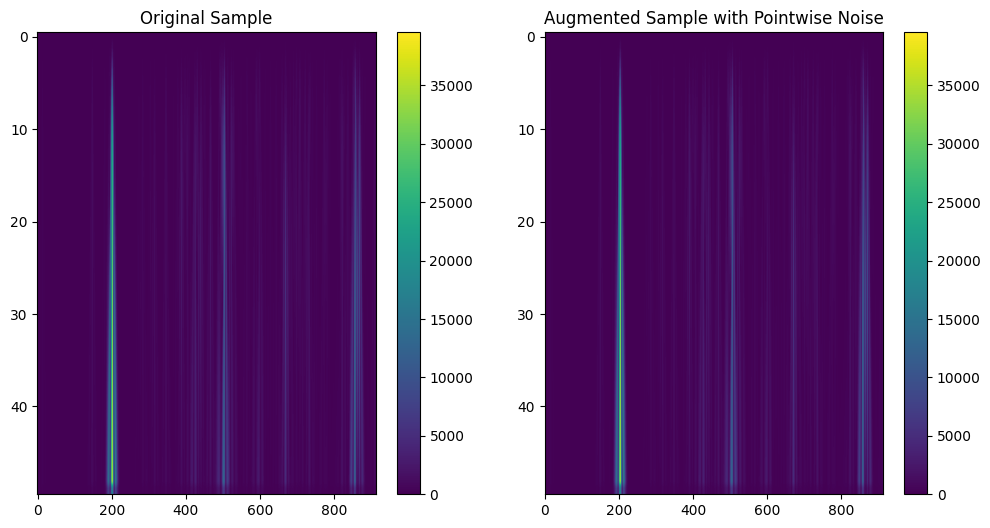

In [45]:
import numpy as np

def augment_data_pointwise(samples, noise_level=0.01):
    # 对每个点添加独立的高斯噪声
    noise = np.random.normal(loc=0.0, scale=noise_level, size=samples.shape)
    augmented_samples = samples + noise
    return augmented_samples

# 假设 processed_samples_array 是一个 (N, 50, 912) 形状的数据集
pooled_samples = np.array([reduce_dimensions(sample.squeeze()) for sample in processed_samples_array])  # 假设已经有了池化后的样本
augmented_samples = augment_data_pointwise(pooled_samples)

# 可视化一个样本的原始和增强效果对比
import matplotlib.pyplot as plt

original_sample = pooled_samples[0]
augmented_sample = augmented_samples[0]

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(original_sample, aspect='auto', cmap='viridis')
plt.title('Original Sample')
plt.colorbar()

plt.subplot(1, 2, 2)
plt.imshow(augmented_sample, aspect='auto', cmap='viridis')
plt.title('Augmented Sample with Pointwise Noise')
plt.colorbar()

plt.show()

In [51]:
def augment_data(samples, num_augments_per_sample=100):
    augmented_samples = []
    for sample in samples:
        for _ in range(num_augments_per_sample):
            sample_aug = sample.copy()
            if np.random.rand() < 0.5:
                sample_aug = time_shift(sample_aug)
            if np.random.rand() < 0.5:
                sample_aug = frequency_mask(sample_aug)
            if np.random.rand() < 0.5:
                sample_aug = time_scale(sample_aug)
            noisy_sample = add_noise(sample_aug)
            augmented_samples.append(noisy_sample)
    return np.array(augmented_samples)
    # 生成增强数据
augmented_samples = augment_data(pooled_samples)
total_augmented_samples = np.concatenate([pooled_samples, augmented_samples], axis=0)


AssertionError: Sample and label counts do not match.

In [58]:
# 原始样本数量
num_original_samples = 123
# 每个原始样本生成的增强样本数量
num_augments_per_sample = 100
# 计算每个原始样本对应的总样本数（包括原始样本自身）
total_samples_per_original = num_augments_per_sample + 1
# 总的样本数
total_samples = num_original_samples * total_samples_per_original

# 现有的标签数组
original_labels = labels  # 假设这是一个包含123个元素的数组

# 复制标签以匹配总样本数
total_labels = np.tile(original_labels, total_samples_per_original)

# 确保复制的标签数组与样本数组长度相匹配
total_augmented_labels = total_labels[:total_samples]


Epoch 1/10
311/311 [==============================] - 901s 3s/step - loss: 1.2774 - accuracy: 0.5914 - val_loss: 0.6758 - val_accuracy: 0.5952
Epoch 2/10
311/311 [==============================] - 1032s 3s/step - loss: 0.6778 - accuracy: 0.5998 - val_loss: 0.6765 - val_accuracy: 0.5960
Epoch 3/10
311/311 [==============================] - 1046s 3s/step - loss: 0.6734 - accuracy: 0.6016 - val_loss: 0.6802 - val_accuracy: 0.5883
Epoch 4/10
311/311 [==============================] - 1042s 3s/step - loss: 0.6681 - accuracy: 0.6079 - val_loss: 0.6871 - val_accuracy: 0.5948
Epoch 5/10
311/311 [==============================] - 1034s 3s/step - loss: 0.6584 - accuracy: 0.6109 - val_loss: 0.6973 - val_accuracy: 0.5408
Epoch 6/10
311/311 [==============================] - 1033s 3s/step - loss: 0.6542 - accuracy: 0.6208 - val_loss: 0.6825 - val_accuracy: 0.5948
Epoch 7/10
311/311 [==============================] - 1048s 3s/step - loss: 0.6358 - accuracy: 0.6377 - val_loss: 0.6910 - val_accuracy: 

<Figure size 1200x1000 with 0 Axes>

<Axes: >

Text(0.5, 1.0, 'Model Accuracy (Original)')

Text(0.5, 0, 'Epoch')

Text(0, 0.5, 'Accuracy')

... (8 outputs left out)

<Axes: >

Text(0.5, 1.0, 'Model Loss (Augmented)')

Text(0.5, 0, 'Epoch')

Text(0, 0.5, 'Loss')

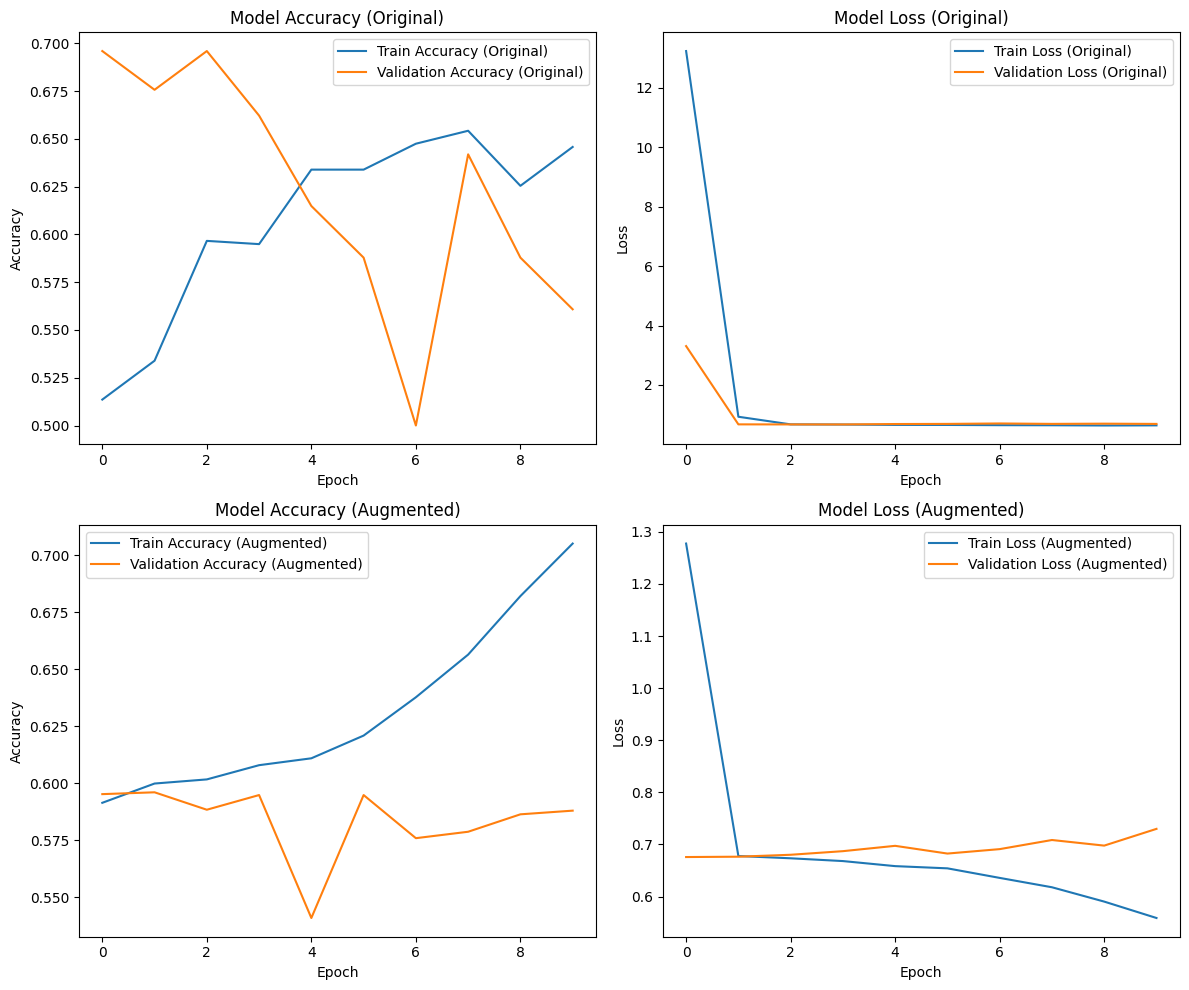

In [59]:
# 划分增强数据集
train_aug_samples, test_aug_samples, train_aug_labels, test_aug_labels = train_test_split(
    total_augmented_samples, total_augmented_labels, test_size=0.2, random_state=42)

# 训练增强模型
model_augmented = build_cnn_model((train_aug_samples.shape[1], train_aug_samples.shape[2], 1))
history_augmented = model_augmented.fit(train_aug_samples, train_aug_labels, epochs=10, batch_size=32, validation_data=(test_aug_samples, test_aug_labels))

# 可视化对比原始和增强数据的训练结果
plt.figure(figsize=(12, 10))
plt.subplot(2, 2, 1)
plt.plot(history_original.history['accuracy'], label='Train Accuracy (Original)')
plt.plot(history_original.history['val_accuracy'], label='Validation Accuracy (Original)')
plt.title('Model Accuracy (Original)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(2, 2, 2)
plt.plot(history_original.history['loss'], label='Train Loss (Original)')
plt.plot(history_original.history['val_loss'], label='Validation Loss (Original)')
plt.title('Model Loss (Original)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(2, 2, 3)
plt.plot(history_augmented.history['accuracy'], label='Train Accuracy (Augmented)')
plt.plot(history_augmented.history['val_accuracy'], label='Validation Accuracy (Augmented)')
plt.title('Model Accuracy (Augmented)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(2, 2, 4)
plt.plot(history_augmented.history['loss'], label='Train Loss (Augmented)')
plt.plot(history_augmented.history['val_loss'], label='Validation Loss (Augmented)')
plt.title('Model Loss (Augmented)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

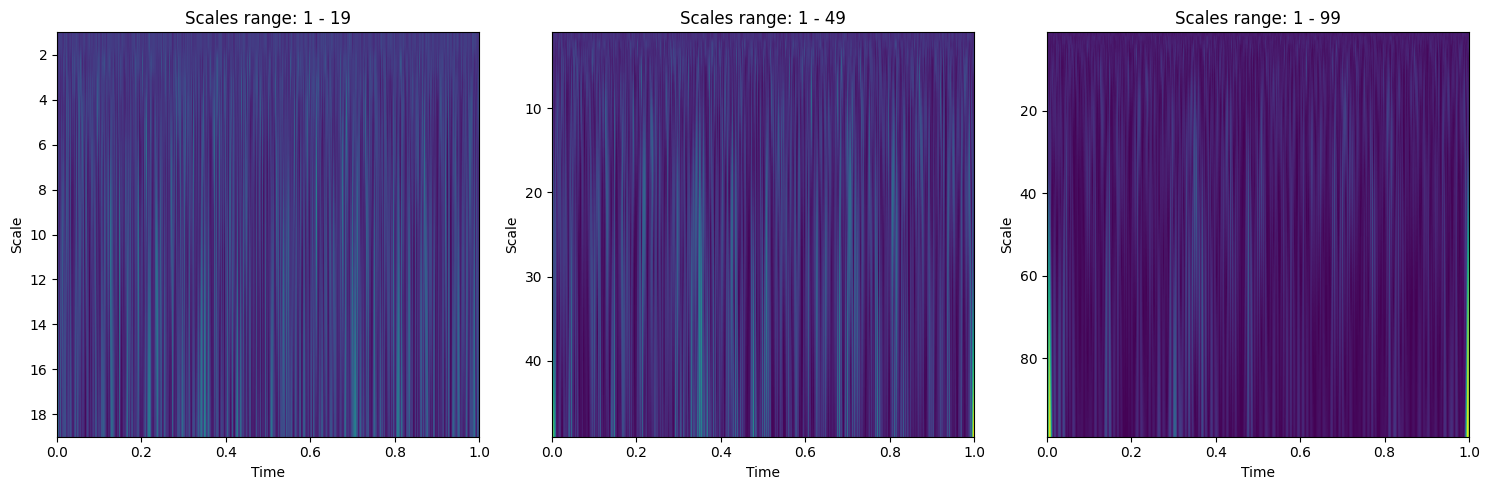

In [63]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt

def generate_spectrogram(spectrogram, scales):
    """
    根据给定的质谱数据和尺度范围生成时频图。
    """
    signal_strength = spectrogram[1]
    wavelet = signal.ricker
    cwt_matrix = signal.cwt(signal_strength, wavelet, scales)
    return np.abs(cwt_matrix)

def evaluate_scales(spectrogram):
    """
    评估不同尺度设置对时频图的影响。
    """
    scale_ranges = [np.arange(1, 20), np.arange(1, 50), np.arange(1, 100)]
    fig, axs = plt.subplots(1, 3, figsize=(15, 5))
    
    for i, scales in enumerate(scale_ranges):
        cwt_matrix = generate_spectrogram(spectrogram, scales)
        ax = axs[i]
        ax.imshow(cwt_matrix, extent=[spectrogram[0].min(), spectrogram[0].max(), scales.max(), scales.min()], aspect='auto')
        ax.set_title(f'Scales range: {scales.min()} - {scales.max()}')
        ax.set_xlabel('Time')
        ax.set_ylabel('Scale')

    plt.tight_layout()
    plt.show()

# 假设你已经有了某个样本的spectrogram
sample_spectrogram = [np.linspace(0, 1, 18229), np.random.rand(18229)]  # 示例数据
evaluate_scales(sample_spectrogram)